Using device: cuda
Loading 1000 patients for train...
Created 438 training windows of shape (438, 48, 5)
Starting Training...
Epoch 1/10 | Loss: 0.11205
Epoch 2/10 | Loss: 0.04759
Epoch 3/10 | Loss: 0.04231
Epoch 4/10 | Loss: 0.03648
Epoch 5/10 | Loss: 0.03830
Epoch 6/10 | Loss: 0.03554
Epoch 7/10 | Loss: 0.03654
Epoch 8/10 | Loss: 0.03391
Epoch 9/10 | Loss: 0.03339
Epoch 10/10 | Loss: 0.03158

Generating Digital Twin Futures...


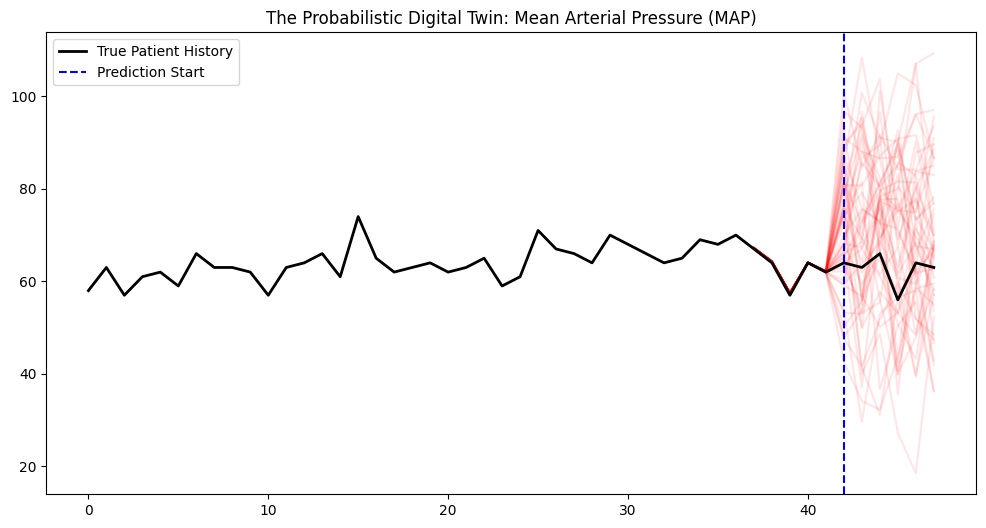

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import math

# ==========================================
# 0. Configuration
# ==========================================
CONFIG = {
    "DATA_PATH": "/content/drive/MyDrive/ColabNotebooks/training_setA-2",
    "VITALS": ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp'],
    "SEQ_LEN": 48,
    "PRED_LEN": 6,
    "BATCH_SIZE": 32,
    "HIDDEN_DIM": 64,
    "DIFFUSION_STEPS": 50,
    "EPOCHS": 10,
    "MAX_FILES": 1000,
    "NUM_WORKERS": 2    # Added for faster data loading
}

# Auto-detect device (CUDA for Nvidia, MPS for Mac, or CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# Optimization for CUDA
if DEVICE.type == 'cuda':
    torch.backends.cudnn.benchmark = True

# ==========================================
# 1. Dataset Loader
# ==========================================
class SepsisDataset(Dataset):
    def __init__(self, data_dir, config, mode='train'):
        self.files = sorted([f for f in os.listdir(data_dir) if f.endswith('.psv')])
        self.files = self.files[:config["MAX_FILES"]]
        self.data_dir = data_dir
        self.vitals = config["VITALS"]
        self.seq_len = config["SEQ_LEN"]
        self.data_cache = []

        print(f"Loading {len(self.files)} patients for {mode}...")

        for f in self.files:
            try:
                df = pd.read_csv(os.path.join(data_dir, f), sep='|')
                df = df[self.vitals]
                df = df.ffill().bfill().fillna(0)

                # Normalize
                norm_vals = {'HR': 100, 'MAP': 100, 'O2Sat': 100, 'SBP': 140, 'Resp': 20}
                for v in self.vitals:
                    df[v] = df[v] / norm_vals[v]

                data = df.values.astype(np.float32)

                if len(data) >= self.seq_len:
                    # Stride of 12 for overlapping windows
                    for i in range(0, len(data) - self.seq_len + 1, 12):
                        window = data[i : i + self.seq_len]
                        self.data_cache.append(window)
            except Exception as e:
                pass # Skip broken files

        self.data_cache = np.array(self.data_cache)
        print(f"Created {len(self.data_cache)} training windows of shape {self.data_cache.shape}")

    def __len__(self):
        return len(self.data_cache)

    def __getitem__(self, idx):
        sample = self.data_cache[idx]
        return torch.tensor(sample).transpose(0, 1)

# ==========================================
# 2. The Diffusion Model
# ==========================================
class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

class ResidualBlock(nn.Module):
    def __init__(self, channels, time_emb_dim):
        super().__init__()
        self.conv1 = nn.Conv1d(channels, channels, 3, padding=1)
        self.conv2 = nn.Conv1d(channels, channels, 3, padding=1)
        self.time_mlp = nn.Linear(time_emb_dim, channels)
        self.bn = nn.BatchNorm1d(channels)
        self.act = nn.LeakyReLU(0.2)

    def forward(self, x, t):
        h = self.conv1(self.act(x))
        time_emb = self.time_mlp(self.act(t)).unsqueeze(-1)
        h = h + time_emb
        h = self.conv2(self.act(h))
        return self.bn(h + x)

class MedicalDiffusion(nn.Module):
    def __init__(self, num_channels, seq_len, hidden_dim=64):
        super().__init__()
        self.time_emb = SinusoidalEmbedding(hidden_dim)
        self.input_proj = nn.Conv1d(num_channels * 2, hidden_dim, 1)
        self.res1 = ResidualBlock(hidden_dim, hidden_dim)
        self.res2 = ResidualBlock(hidden_dim, hidden_dim)
        self.res3 = ResidualBlock(hidden_dim, hidden_dim)
        self.res4 = ResidualBlock(hidden_dim, hidden_dim)
        self.output_proj = nn.Conv1d(hidden_dim, num_channels, 1)

    def forward(self, x, mask, t):
        x_in = torch.cat([x, mask], dim=1)
        t_emb = self.time_emb(t)
        h = self.input_proj(x_in)
        h = self.res1(h, t_emb)
        h = self.res2(h, t_emb)
        h = self.res3(h, t_emb)
        h = self.res4(h, t_emb)
        return self.output_proj(h)

# ==========================================
# 3. Training & Inference
# ==========================================
def get_beta_schedule(steps):
    return torch.linspace(0.0001, 0.02, steps)

def train_model():
    dataset = SepsisDataset(CONFIG["DATA_PATH"], CONFIG)

    # GPU OPTIMIZATION: pin_memory and num_workers
    dataloader = DataLoader(
        dataset,
        batch_size=CONFIG["BATCH_SIZE"],
        shuffle=True,
        pin_memory=True if DEVICE.type == 'cuda' else False,
        num_workers=CONFIG["NUM_WORKERS"]
    )

    model = MedicalDiffusion(len(CONFIG["VITALS"]), CONFIG["SEQ_LEN"], CONFIG["HIDDEN_DIM"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    betas = get_beta_schedule(CONFIG["DIFFUSION_STEPS"]).to(DEVICE)
    alphas = 1. - betas
    alphas_cumprod = torch.cumprod(alphas, dim=0)

    print("Starting Training...")
    model.train()

    for epoch in range(CONFIG["EPOCHS"]):
        total_loss = 0
        for batch in dataloader:
            batch = batch.to(DEVICE) # Move batch to GPU

            mask = torch.ones_like(batch)
            mask[:, :, -CONFIG["PRED_LEN"]:] = 0

            noise = torch.randn_like(batch)
            t = torch.randint(0, CONFIG["DIFFUSION_STEPS"], (batch.shape[0],), device=DEVICE)

            alpha_bar = alphas_cumprod[t].reshape(-1, 1, 1)
            noisy_input = torch.sqrt(alpha_bar) * batch + torch.sqrt(1 - alpha_bar) * noise

            model_input = mask * batch + (1 - mask) * noisy_input

            pred_noise = model(model_input, mask, t)
            loss = F.mse_loss(pred_noise * (1-mask), noise * (1-mask))

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{CONFIG['EPOCHS']} | Loss: {total_loss/len(dataloader):.5f}")

    return model, dataset

def generate_digital_twin(model, patient_data, device):
    model.eval()
    n_samples = 50

    # Ensure patient_data is on device
    patient_data = patient_data.to(device)

    x = patient_data.unsqueeze(0).repeat(n_samples, 1, 1) # (50, Channels, Time)
    mask = torch.ones_like(x)
    mask[:, :, -CONFIG["PRED_LEN"]:] = 0

    curr_img = torch.randn_like(x)

    betas = get_beta_schedule(CONFIG["DIFFUSION_STEPS"]).to(device)
    alphas = 1. - betas
    alphas_cumprod = torch.cumprod(alphas, dim=0)

    for t in reversed(range(CONFIG["DIFFUSION_STEPS"])):
        # Impute known past
        curr_img = mask * x + (1 - mask) * curr_img

        t_tensor = torch.full((n_samples,), t, device=device, dtype=torch.long)

        with torch.no_grad():
            pred_noise = model(curr_img, mask, t_tensor)

        alpha = alphas[t]
        alpha_bar = alphas_cumprod[t]
        beta = betas[t]
        z = torch.randn_like(curr_img) if t > 0 else 0

        curr_img = (1 / torch.sqrt(alpha)) * (curr_img - ((1 - alpha) / torch.sqrt(1 - alpha_bar)) * pred_noise) + torch.sqrt(beta) * z

    return curr_img.cpu().numpy()

# ==========================================
# 4. Main Execution
# ==========================================
if __name__ == "__main__":
    if not os.path.exists(CONFIG["DATA_PATH"]):
        print("Error: Data path not found.")
    else:
        model, dataset = train_model()

        idx = np.random.randint(0, len(dataset))
        patient_sample = dataset[idx] # Returns CPU tensor

        print("\nGenerating Digital Twin Futures...")
        futures = generate_digital_twin(model, patient_sample, DEVICE)

        # Plotting
        vital_idx = 1
        vital_name = "Mean Arterial Pressure (MAP)"
        plt.figure(figsize=(12, 6))

        split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]
        scale_factor = 100.0

        for i in range(50):
            plt.plot(range(split_pt-5, CONFIG["SEQ_LEN"]),
                     futures[i, vital_idx, split_pt-5:] * scale_factor,
                     color='red', alpha=0.1)

        truth = patient_sample[vital_idx].numpy() * scale_factor
        plt.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2, label="True Patient History")

        plt.axvline(x=split_pt, color='blue', linestyle='--', label="Prediction Start")
        plt.title(f"The Probabilistic Digital Twin: {vital_name}")
        plt.legend()
        plt.show()

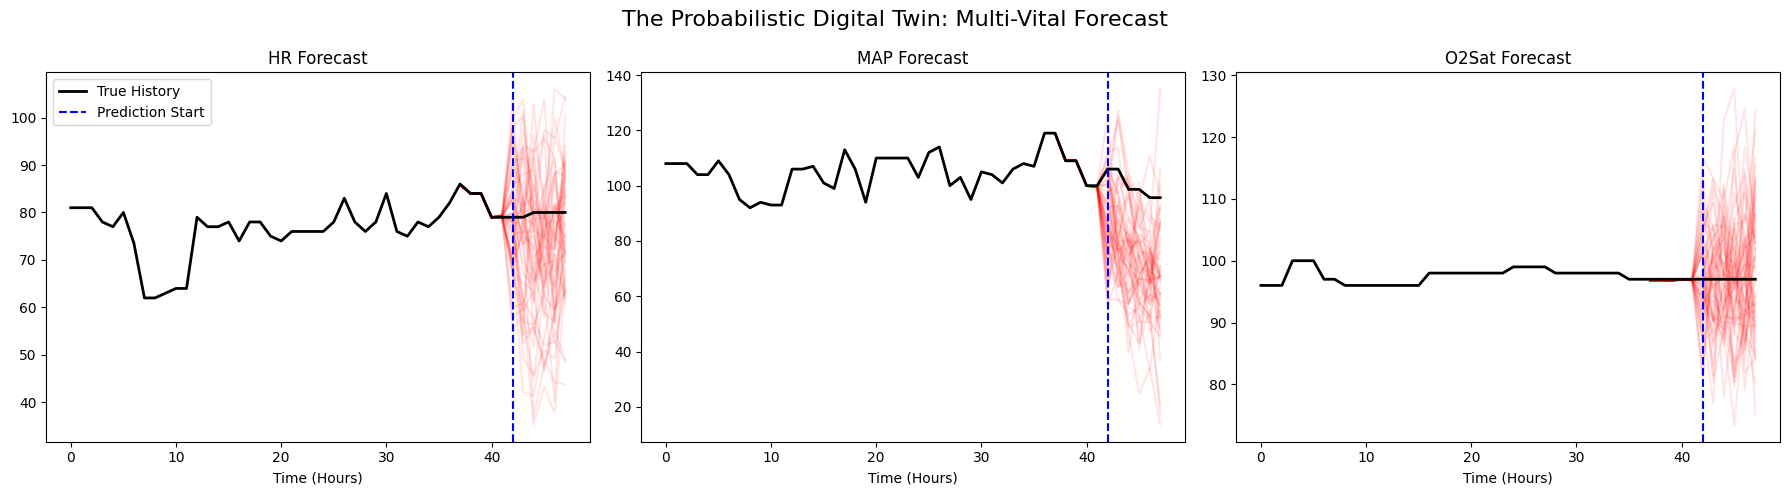

In [2]:
# ==========================================
# VISUALIZATION: The Full Digital Twin Dashboard
# ==========================================
def plot_full_dashboard(model, dataset, device):
    # 1. Pick a random patient
    idx = np.random.randint(0, len(dataset))
    patient_sample = dataset[idx] # Shape: (5, 48)

    # 2. Generate Futures
    # futures shape: (50, 5, 48)
    futures = generate_digital_twin(model, patient_sample, device)

    # 3. Setup Plot
    vitals = CONFIG["VITALS"] # ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp']
    # We will plot HR, MAP, and O2Sat (Indices 0, 1, 2)
    plot_indices = [0, 1, 2]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]
    # Scales to make the plot look like real units
    scales = {'HR': 100, 'MAP': 100, 'O2Sat': 100, 'SBP': 140, 'Resp': 20}

    for ax_idx, vital_idx in enumerate(plot_indices):
        name = vitals[vital_idx]
        scale = scales[name]
        ax = axes[ax_idx]

        # Plot 50 Futures
        for i in range(50):
            ax.plot(range(split_pt-5, CONFIG["SEQ_LEN"]),
                     futures[i, vital_idx, split_pt-5:] * scale,
                     color='red', alpha=0.1)

        # Plot True History
        truth = patient_sample[vital_idx].numpy() * scale
        ax.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2, label="True History")

        # Formatting
        ax.axvline(x=split_pt, color='blue', linestyle='--', label="Prediction Start")
        ax.set_title(f"{name} Forecast")
        ax.set_xlabel("Time (Hours)")
        if ax_idx == 0: ax.legend()

    plt.suptitle(f"The Probabilistic Digital Twin: Multi-Vital Forecast", fontsize=16)
    plt.tight_layout()
    plt.show()

# Run the dashboard
plot_full_dashboard(model, dataset, DEVICE)